1.1 Choose the Dataset

Determine a common date range for all five weather stations and clearly state the start 
and end dates you use for modelling. Your selected date range must contain data for all 
five stations. Briefly justify your selection based on the data availability across the 
stations. The end date does not have to be in 2026. 
You must load and use all six files as model inputs, extracting the specific variables 
listed in Table 2. The required variables from each file must be merged by date to 
construct the input dataset for model development and forecasting. 
Target variable: Mean Temperature [°C] from the Temperature file, forecast 7 days 
ahead (multi-step output). 
Total input features per station: 3 evaporation values + 3 temperature sub-variables 
(min, max, mean temp) + wind speed + rainfall = 8 features per time step. 
Perform a correlation coefficient of the parameters and report the relationship between 
the input features and the target. 

First I will load the dataset to check the date range of these files 

In [1]:
# Load the six file of 4843
import pandas as pd

CA_open_eva = pd.read_csv("../data/raw/4843__Evaporation__Penman-Open-Water-Evaporation__daily.csv")
CA_open_eva["Observation time UTC"] = pd.to_datetime(
    CA_open_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

print(CA_open_eva.head())
print(CA_open_eva.shape)

CA_pet_eva = pd.read_csv("../data/raw/4843__Evaporation__Penman-PET__daily.csv")
CA_pet_eva["Observation time UTC"] = pd.to_datetime(
    CA_pet_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)
print(CA_pet_eva.head())
print(CA_pet_eva.shape)

CA_pri_eva = pd.read_csv("../data/raw/4843__Evaporation__Priestly-Taylor-PET__daily.csv")
CA_pri_eva["Observation time UTC"] = pd.to_datetime(
    CA_pri_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)
print(CA_pri_eva.head())
print(CA_pri_eva.shape)

CA_rain = pd.read_csv("../data/raw/4843__Rain__daily.csv")
CA_rain["Observation time UTC"] = pd.to_datetime(
    CA_rain["Observation time UTC"],
   format="ISO8601",
    utc=True
)
print(CA_rain.head())
print(CA_rain.shape)

CA_wind = pd.read_csv("../data/raw/4843__Wind__daily.csv")
CA_wind["Observation time UTC"] = pd.to_datetime(
    CA_wind["Observation time UTC"],
   format="ISO8601",
    utc=True
)
print(CA_wind.head())
print(CA_wind.shape)

CA_temp = pd.read_csv("../data/raw/4843__Temperature__daily.csv")
CA_temp["Observation time UTC"] = pd.to_datetime(
    CA_temp["Observation time UTC"],
   format="ISO8601",
    utc=True
)
print(CA_temp.head())
print(CA_temp.shape)

  Data Source                      Data Type      Observation time UTC  \
0           F  Penman Open Water Evaporation 1960-01-01 21:00:00+00:00   
1           F  Penman Open Water Evaporation 1960-01-02 21:00:00+00:00   
2           F  Penman Open Water Evaporation 1960-01-03 21:00:00+00:00   
3           F  Penman Open Water Evaporation 1960-01-04 21:00:00+00:00   
4           F  Penman Open Water Evaporation 1960-01-05 21:00:00+00:00   

   Evaporation [mm]  PERIOD [hrs]  
0               4.8            24  
1               9.1            24  
2               6.2            24  
3               4.1            24  
4               0.9            24  
(24222, 5)
  Data Source   Data Type      Observation time UTC  Evaporation [mm]  \
0           F  Penman PET 1960-01-01 21:00:00+00:00               6.1   
1           F  Penman PET 1960-01-02 21:00:00+00:00               5.9   
2           F  Penman PET 1960-01-03 21:00:00+00:00               6.6   
3           F  Penman PET 1960-01-04

We can see that the files have the similar Date column in terms of format, so for the next step I will merge these files together 

In [2]:
CA_merged_1 = pd.merge(CA_open_eva[["Observation time UTC", "Evaporation [mm]"]],CA_pet_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")


print(CA_merged_1.head())
print(CA_merged_1.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y
0 1960-01-01 21:00:00+00:00                 4.8                 6.1
1 1960-01-02 21:00:00+00:00                 9.1                 5.9
2 1960-01-03 21:00:00+00:00                 6.2                 6.6
3 1960-01-04 21:00:00+00:00                 4.1                 4.1
4 1960-01-05 21:00:00+00:00                 0.9                 2.1
(24222, 3)


In [3]:
CA_merged_2 = pd.merge(CA_merged_1[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y"]],CA_pri_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")

print(CA_merged_2.head())
print(CA_merged_2.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1960-01-01 21:00:00+00:00                 4.8                 6.1   
1 1960-01-02 21:00:00+00:00                 9.1                 5.9   
2 1960-01-03 21:00:00+00:00                 6.2                 6.6   
3 1960-01-04 21:00:00+00:00                 4.1                 4.1   
4 1960-01-05 21:00:00+00:00                 0.9                 2.1   

   Evaporation [mm]  
0               5.8  
1               2.9  
2               5.5  
3               3.2  
4               2.6  
(22867, 4)


In [4]:
CA_merged_3 = pd.merge(CA_merged_2[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]"]],CA_rain[["Observation time UTC", "Rainfall [mm]"]], on="Observation time UTC", how="inner")

print(CA_merged_3.head())
print(CA_merged_3.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1960-01-01 21:00:00+00:00                 4.8                 6.1   
1 1960-01-02 21:00:00+00:00                 9.1                 5.9   
2 1960-01-03 21:00:00+00:00                 6.2                 6.6   
3 1960-01-04 21:00:00+00:00                 4.1                 4.1   
4 1960-01-05 21:00:00+00:00                 0.9                 2.1   

   Evaporation [mm]  Rainfall [mm]  
0               5.8            0.0  
1               2.9            0.0  
2               5.5            0.0  
3               3.2            1.3  
4               2.6            7.4  
(22867, 5)


In [5]:
CA_merged_4 = pd.merge(CA_merged_3[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]"]],CA_wind[["Observation time UTC", "Speed [m/s]"]], on="Observation time UTC", how="inner")

print(CA_merged_4.head())
print(CA_merged_4.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1994-07-07 21:00:00+00:00                 3.3                 1.6   
1 1994-07-08 21:00:00+00:00                 0.9                 0.5   
2 1994-07-09 21:00:00+00:00                 2.3                 0.9   
3 1994-07-10 21:00:00+00:00                 3.5                 1.6   
4 1994-07-11 21:00:00+00:00                 2.4                 1.2   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  
0               0.0            5.8         4.57  
1               0.0            0.0         6.25  
2               0.0            0.0         2.43  
3               0.0            0.0         4.34  
4               0.0            3.9         4.44  
(11372, 6)


When I merge the data for temperature, as my model will focus on temperature 7 days head so I will merge with the temperature data of 7 days ahead 

In [6]:
CA_merged = pd.merge(CA_merged_4[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]", "Speed [m/s]"]],CA_temp[["Observation time UTC", "Maximum Temperature [Deg C]", "Minimum Temperature [Deg C]", "Mean Temperature [Deg C]"  ]], on="Observation time UTC", how="inner")

print(CA_merged.head())
print(CA_merged.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1994-07-07 21:00:00+00:00                 3.3                 1.6   
1 1994-07-08 21:00:00+00:00                 0.9                 0.5   
2 1994-07-09 21:00:00+00:00                 2.3                 0.9   
3 1994-07-10 21:00:00+00:00                 3.5                 1.6   
4 1994-07-11 21:00:00+00:00                 2.4                 1.2   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               0.0            5.8         4.57                         13.6   
1               0.0            0.0         6.25                          8.6   
2               0.0            0.0         2.43                         10.9   
3               0.0            0.0         4.34                         16.9   
4               0.0            3.9         4.44                          9.3   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C]  
0                          0.0   

In [7]:
# Convert the date/time
CA_merged["Observation time UTC"] = pd.to_datetime(
    CA_merged["Observation time UTC"],
   format="ISO8601",
    utc=True
)


CA_merged = CA_merged.sort_values("Observation time UTC")


print(CA_merged["Observation time UTC"].min())
print(CA_merged["Observation time UTC"].max())

1994-07-07 21:00:00+00:00
2026-08-11 21:00:00+00:00


We check the missing value of the mean teamperature 

In [8]:
# Check missing values first:
print(CA_merged["Mean Temperature [Deg C]"].isnull().sum())

6


If there is a missing value between two known values, estimate it based on the values before and after it.

In [9]:
# fill missing values with interpolate method
CA_merged["Mean Temperature [Deg C]"] = CA_merged["Mean Temperature [Deg C]"].interpolate(
    method="linear"
)

CA_merged["Mean Temperature [Deg C]"] = CA_merged["Mean Temperature [Deg C]"].ffill().bfill()

# Check missing values again:
print(CA_merged["Mean Temperature [Deg C]"].isnull().sum())

0


So after this, I have no missing value

Then we add a column Station to this dataset 

In [10]:
CA_merged["Station"] = "CA"
print(CA_merged.head())
print(CA_merged.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1994-07-07 21:00:00+00:00                 3.3                 1.6   
1 1994-07-08 21:00:00+00:00                 0.9                 0.5   
2 1994-07-09 21:00:00+00:00                 2.3                 0.9   
3 1994-07-10 21:00:00+00:00                 3.5                 1.6   
4 1994-07-11 21:00:00+00:00                 2.4                 1.2   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               0.0            5.8         4.57                         13.6   
1               0.0            0.0         6.25                          8.6   
2               0.0            0.0         2.43                         10.9   
3               0.0            0.0         4.34                         16.9   
4               0.0            3.9         4.44                          9.3   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C] Station  
0                        

So we have the dataset here in which  Mean Temperature [Deg C]_y is the mean temperature after 7 days

In the next step, I will do similar for the dataset of Christchurch, Kyle St EWS station

In [11]:

import pandas as pd

CK_open_eva = pd.read_csv("../data/raw/24120__Evaporation__Penman-Open-Water-Evaporation__daily.csv")
CK_open_eva["Observation time UTC"] = pd.to_datetime(
    CK_open_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

CK_pet_eva = pd.read_csv("../data/raw/24120__Evaporation__Penman-PET__daily.csv")
CK_pet_eva["Observation time UTC"] = pd.to_datetime(
    CK_pet_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

CK_pri_eva = pd.read_csv("../data/raw/24120__Evaporation__Priestly-Taylor-PET__daily.csv")
CK_pri_eva["Observation time UTC"] = pd.to_datetime(
    CK_pri_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

CK_rain = pd.read_csv("../data/raw/24120__Rain__daily.csv")
CK_rain["Observation time UTC"] = pd.to_datetime(
    CK_rain["Observation time UTC"],
   format="ISO8601",
    utc=True
)

CK_wind = pd.read_csv("../data/raw/24120__Wind__daily.csv")
CK_wind["Observation time UTC"] = pd.to_datetime(
    CK_wind["Observation time UTC"],
   format="ISO8601",
    utc=True
)

CK_temp = pd.read_csv("../data/raw/24120__Temperature__daily.csv")
CK_temp["Observation time UTC"] = pd.to_datetime(
    CK_temp["Observation time UTC"],
   format="ISO8601",
    utc=True
)

CK_merged_1 = pd.merge(CK_open_eva[["Observation time UTC", "Evaporation [mm]"]],CK_pet_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")


CK_merged_2 = pd.merge(CK_merged_1[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y"]],CK_pri_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")

CK_merged_3 = pd.merge(CK_merged_2[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]"]],CK_rain[["Observation time UTC", "Rainfall [mm]"]], on="Observation time UTC", how="inner")

CK_merged_4 = pd.merge(CK_merged_3[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]"]],CK_wind[["Observation time UTC", "Speed [m/s]"]], on="Observation time UTC", how="inner")

CK_merged = pd.merge(CK_merged_4[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]", "Speed [m/s]"]],CK_temp[["Observation time UTC", "Maximum Temperature [Deg C]", "Minimum Temperature [Deg C]", "Mean Temperature [Deg C]"  ]], on="Observation time UTC", how="inner")

CK_merged = CK_merged.sort_values("Observation time UTC")



print(CK_merged.head())
print(CK_merged.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 2002-11-01 20:00:00+00:00                 7.9                 6.5   
1 2002-11-02 20:00:00+00:00                 2.1                 2.3   
2 2002-11-03 20:00:00+00:00                 3.3                 2.9   
3 2002-11-04 20:00:00+00:00                 3.9                 4.0   
4 2002-11-05 20:00:00+00:00                 5.7                 5.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.6            0.0         4.09                         23.9   
1               1.9            0.0         4.00                         11.5   
2               2.3            0.0         1.88                         14.2   
3               3.4            0.0         2.73                         17.4   
4               4.3            0.0         3.90                         25.7   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C]  
0                          8.5   

The next step of checking missing value

In [12]:
print(CK_merged["Mean Temperature [Deg C]"].isnull().sum())

1


In [13]:
# fill missing values with interpolate method
CK_merged["Mean Temperature [Deg C]"] = CK_merged["Mean Temperature [Deg C]"].interpolate(
    method="linear"
)

CK_merged["Mean Temperature [Deg C]"] = CK_merged["Mean Temperature [Deg C]"].ffill().bfill()

# Check missing values again:
print(CK_merged["Mean Temperature [Deg C]"].isnull().sum())

0


In [14]:
CK_merged["Station"] = "CK"

In the next step I merge the tables for ASHBURTON AERO AWS 

In [16]:
# Load the six file of 4843
import pandas as pd

AA_open_eva = pd.read_csv("../data/raw/26170__Evaporation__Penman-Open-Water-Evaporation__daily.csv")

AA_pet_eva = pd.read_csv("../data/raw/26170__Evaporation__Penman-PET__daily.csv")

AA_pri_eva = pd.read_csv("../data/raw/26170__Evaporation__Priestly-Taylor-PET__daily.csv")

AA_rain = pd.read_csv("../data/raw/26170__Rain__daily.csv")

AA_wind = pd.read_csv("../data/raw/24120__Wind__daily.csv")

AA_temp = pd.read_csv("../data/raw/26170__Temperature__daily.csv")

AA_open_eva["Observation time UTC"] = pd.to_datetime(
    AA_open_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

AA_pet_eva["Observation time UTC"] = pd.to_datetime(
    AA_pet_eva["Observation time UTC"],
   format="ISO8601",
    utc=True)

AA_pri_eva["Observation time UTC"] = pd.to_datetime(
    AA_pri_eva["Observation time UTC"],
   format="ISO8601",
    utc=True)

AA_rain["Observation time UTC"] = pd.to_datetime(
    AA_rain["Observation time UTC"],
   format="ISO8601",
    utc=True
)

AA_wind["Observation time UTC"] = pd.to_datetime(
    AA_wind["Observation time UTC"],
   format="ISO8601",
    utc=True
)

AA_temp["Observation time UTC"] = pd.to_datetime(
    AA_temp["Observation time UTC"],
   format="ISO8601",
    utc=True
)
AA_merged_1 = pd.merge(AA_open_eva[["Observation time UTC", "Evaporation [mm]"]],AA_pet_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")


AA_merged_2 = pd.merge(AA_merged_1[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y"]],AA_pri_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")

AA_merged_3 = pd.merge(AA_merged_2[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]"]],AA_rain[["Observation time UTC", "Rainfall [mm]"]], on="Observation time UTC", how="inner")

AA_merged_4 = pd.merge(AA_merged_3[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]"]],AA_wind[["Observation time UTC", "Speed [m/s]"]], on="Observation time UTC", how="inner")

AA_merged = pd.merge(AA_merged_4[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]", "Speed [m/s]"]],AA_temp[["Observation time UTC", "Maximum Temperature [Deg C]", "Minimum Temperature [Deg C]", "Mean Temperature [Deg C]"  ]], on="Observation time UTC", how="inner")

AA_merged = AA_merged.sort_values("Observation time UTC")


print(AA_merged.head())
print(AA_merged.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 2006-02-11 20:00:00+00:00                 6.5                 5.5   
1 2006-02-12 20:00:00+00:00                 8.6                 6.3   
2 2006-02-13 20:00:00+00:00                 4.5                 4.3   
3 2006-02-14 20:00:00+00:00                 2.9                 2.3   
4 2006-02-15 20:00:00+00:00                 2.0                 3.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.0            0.0         3.01                         26.7   
1               4.2            0.0         3.17                         29.3   
2               3.4            0.0         4.10                         20.6   
3               1.7            0.4         2.34                         22.5   
4               3.5            0.0         3.10                         19.7   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C]  
0                         14.5   

In [17]:
print(AA_merged["Mean Temperature [Deg C]"].isnull().sum())

26


In [18]:
# fill missing values with interpolate method
AA_merged["Mean Temperature [Deg C]"] = AA_merged["Mean Temperature [Deg C]"].interpolate(
    method="linear"
)

AA_merged["Mean Temperature [Deg C]"] = AA_merged["Mean Temperature [Deg C]"].ffill().bfill()

# Check missing values again:
print(AA_merged["Mean Temperature [Deg C]"].isnull().sum())

0


In [19]:

AA_merged["Station"] = "AA"
print(AA_merged.head())
print(AA_merged.shape)


       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 2006-02-11 20:00:00+00:00                 6.5                 5.5   
1 2006-02-12 20:00:00+00:00                 8.6                 6.3   
2 2006-02-13 20:00:00+00:00                 4.5                 4.3   
3 2006-02-14 20:00:00+00:00                 2.9                 2.3   
4 2006-02-15 20:00:00+00:00                 2.0                 3.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.0            0.0         3.01                         26.7   
1               4.2            0.0         3.17                         29.3   
2               3.4            0.0         4.10                         20.6   
3               1.7            0.4         2.34                         22.5   
4               3.5            0.0         3.10                         19.7   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C] Station  
0                        

In the next step I merge the dataset for Rangiora EWS 

In [20]:
# Load the six file of 4843
import pandas as pd

RE_open_eva = pd.read_csv("../data/raw/17244__Evaporation__Penman-Open-Water-Evaporation__daily.csv")

RE_pet_eva = pd.read_csv("../data/raw/17244__Evaporation__Penman-PET__daily.csv")

RE_pri_eva = pd.read_csv("../data/raw/17244__Evaporation__Priestly-Taylor-PET__daily.csv")

RE_rain = pd.read_csv("../data/raw/17244__Rain__daily.csv")

RE_wind = pd.read_csv("../data/raw/17244__Wind__daily.csv")

RE_temp = pd.read_csv("../data/raw/17244__Temperature__daily.csv")

RE_open_eva["Observation time UTC"] = pd.to_datetime(
    RE_open_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

RE_pet_eva["Observation time UTC"] = pd.to_datetime(
    RE_pet_eva["Observation time UTC"],
   format="ISO8601",
    utc=True)

RE_pri_eva["Observation time UTC"] = pd.to_datetime(
    RE_pri_eva["Observation time UTC"],
   format="ISO8601",
    utc=True)

RE_rain["Observation time UTC"] = pd.to_datetime(
    RE_rain["Observation time UTC"],
   format="ISO8601",
    utc=True
)

RE_wind["Observation time UTC"] = pd.to_datetime(
    RE_wind["Observation time UTC"],
   format="ISO8601",
    utc=True
)

RE_temp["Observation time UTC"] = pd.to_datetime(
    RE_temp["Observation time UTC"],
   format="ISO8601",
    utc=True)

RE_merged_1 = pd.merge(RE_open_eva[["Observation time UTC", "Evaporation [mm]"]],RE_pet_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")


RE_merged_2 = pd.merge(RE_merged_1[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y"]],RE_pri_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")

RE_merged_3 = pd.merge(RE_merged_2[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]"]],RE_rain[["Observation time UTC", "Rainfall [mm]"]], on="Observation time UTC", how="inner")

RE_merged_4 = pd.merge(RE_merged_3[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]"]],RE_wind[["Observation time UTC", "Speed [m/s]"]], on="Observation time UTC", how="inner")

RE_merged = pd.merge(RE_merged_4[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]", "Speed [m/s]"]],RE_temp[["Observation time UTC", "Maximum Temperature [Deg C]", "Minimum Temperature [Deg C]", "Mean Temperature [Deg C]"  ]], on="Observation time UTC", how="inner")


RE_merged = RE_merged.sort_values("Observation time UTC")

print(RE_merged.head())
print(RE_merged.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1999-02-18 20:00:00+00:00                 5.1                 5.2   
1 1999-02-19 20:00:00+00:00                 7.4                 5.0   
2 1999-02-20 20:00:00+00:00                 6.9                 4.5   
3 1999-02-21 20:00:00+00:00                 3.5                 4.2   
4 1999-02-22 20:00:00+00:00                 3.6                 4.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.8            0.0         2.93                         26.6   
1               2.5            0.0         5.31                         26.9   
2               2.7            0.0         2.63                         22.8   
3               3.9            0.0         3.53                         20.2   
4               3.9            0.0         4.73                         19.9   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C]  
0                         11.1   

In [21]:
print(RE_merged["Mean Temperature [Deg C]"].isnull().sum())

17


In [22]:
# fill missing values with interpolate method
RE_merged["Mean Temperature [Deg C]"] = RE_merged["Mean Temperature [Deg C]"].interpolate(
    method="linear"
)

RE_merged["Mean Temperature [Deg C]"] = RE_merged["Mean Temperature [Deg C]"].ffill().bfill()

# Check missing values again:
print(RE_merged["Mean Temperature [Deg C]"].isnull().sum())

0


In [23]:


RE_merged["Station"] = "RE"
print(RE_merged.head())
print(RE_merged.shape)


       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1999-02-18 20:00:00+00:00                 5.1                 5.2   
1 1999-02-19 20:00:00+00:00                 7.4                 5.0   
2 1999-02-20 20:00:00+00:00                 6.9                 4.5   
3 1999-02-21 20:00:00+00:00                 3.5                 4.2   
4 1999-02-22 20:00:00+00:00                 3.6                 4.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.8            0.0         2.93                         26.6   
1               2.5            0.0         5.31                         26.9   
2               2.7            0.0         2.63                         22.8   
3               3.9            0.0         3.53                         20.2   
4               3.9            0.0         4.73                         19.9   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C] Station  
0                        

In [29]:
RE_merged = RE_merged.rename(
    columns={"Observation time UTC": "Observation time UTC_x"})

In the next steop, I merge the dataset for Hanmer Forest EWS 

In [24]:
# Load the six file of 4843
import pandas as pd

HF_open_eva = pd.read_csv("../data/raw/11234__Evaporation__Penman-Open-Water-Evaporation__daily.csv")

HF_pet_eva = pd.read_csv("../data/raw/11234__Evaporation__Penman-PET__daily.csv")

HF_pri_eva = pd.read_csv("../data/raw/11234__Evaporation__Priestly-Taylor-PET__daily.csv")

HF_rain = pd.read_csv("../data/raw/11234__Rain__daily.csv")

HF_wind = pd.read_csv("../data/raw/11234__Wind__daily.csv")

HF_temp = pd.read_csv("../data/raw/11234__Temperature__daily.csv")

HF_open_eva["Observation time UTC"] = pd.to_datetime(
    HF_open_eva["Observation time UTC"],
   format="ISO8601",
    utc=True
)

HF_pet_eva["Observation time UTC"] = pd.to_datetime(
    HF_pet_eva["Observation time UTC"],
   format="ISO8601",
    utc=True)

HF_pri_eva["Observation time UTC"] = pd.to_datetime(
    HF_pri_eva["Observation time UTC"],
   format="ISO8601",
    utc=True)

HF_rain["Observation time UTC"] = pd.to_datetime(
    HF_rain["Observation time UTC"],
   format="ISO8601",
    utc=True
)

HF_wind["Observation time UTC"] = pd.to_datetime(
    HF_wind["Observation time UTC"],
   format="ISO8601",
    utc=True
)

HF_temp["Observation time UTC"] = pd.to_datetime(
    HF_temp["Observation time UTC"],
   format="ISO8601",
    utc=True)

HF_merged_1 = pd.merge(HF_open_eva[["Observation time UTC", "Evaporation [mm]"]],HF_pet_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")


HF_merged_2 = pd.merge(HF_merged_1[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y"]],HF_pri_eva[["Observation time UTC", "Evaporation [mm]"]], on="Observation time UTC", how="inner")

HF_merged_3 = pd.merge(HF_merged_2[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]"]],HF_rain[["Observation time UTC", "Rainfall [mm]"]], on="Observation time UTC", how="inner")

HF_merged_4 = pd.merge(HF_merged_3[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]"]],HF_wind[["Observation time UTC", "Speed [m/s]"]], on="Observation time UTC", how="inner")

HF_merged = pd.merge(HF_merged_4[["Observation time UTC", "Evaporation [mm]_x",  "Evaporation [mm]_y",  "Evaporation [mm]", "Rainfall [mm]", "Speed [m/s]"]],HF_temp[["Observation time UTC", "Maximum Temperature [Deg C]", "Minimum Temperature [Deg C]", "Mean Temperature [Deg C]"  ]], on="Observation time UTC", how="inner")

HF_merged = HF_merged.sort_values("Observation time UTC")



HF_merged["Station"] = "HF"

print(HF_merged.head())
print(HF_merged.shape)

       Observation time UTC  Evaporation [mm]_x  Evaporation [mm]_y  \
0 1996-10-30 20:00:00+00:00                 4.1                 4.6   
1 1996-10-31 20:00:00+00:00                 4.2                 3.9   
2 1996-11-01 20:00:00+00:00                 0.4                 0.7   
3 1996-11-02 20:00:00+00:00                 1.9                 2.5   
4 1996-11-03 20:00:00+00:00                 1.2                 1.6   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.1            0.0         2.84                         23.0   
1               3.0            2.4         2.92                         19.2   
2               0.8            2.0         1.02                          6.5   
3               2.5            0.0         1.33                         15.2   
4               1.6            7.6         1.09                         14.5   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C] Station  
0                        

In the next step I identify the common time range of the five datasets

In [ ]:
print(HF_merged["Mean Temperature [Deg C]"].isnull().sum())



14


In [26]:
# fill missing values with interpolate method
HF_merged["Mean Temperature [Deg C]"] = HF_merged["Mean Temperature [Deg C]"].interpolate(
    method="linear"
)

HF_merged["Mean Temperature [Deg C]"] = HF_merged["Mean Temperature [Deg C]"].ffill().bfill()

# Check missing values again:
print(HF_merged["Mean Temperature [Deg C]"].isnull().sum())

0


In [30]:
HF_merged = HF_merged.rename(
    columns={"Observation time UTC": "Observation time UTC_x"})

CA_merged = CA_merged.rename(
    columns={"Observation time UTC": "Observation time UTC_x"})

AA_merged = AA_merged.rename(
    columns={"Observation time UTC": "Observation time UTC_x"})

CK_merged = CK_merged.rename(
    columns={"Observation time UTC": "Observation time UTC_x"})

In [31]:
import pandas as pd

Time_range = pd.DataFrame({
    "Dataset": ["CA", "CK", "AA","RE","HF"],

    "Min Date": [
        min(CA_merged["Observation time UTC_x"]), 
        min(CK_merged["Observation time UTC_x"]), 
        min(AA_merged["Observation time UTC_x"]),
        min(RE_merged["Observation time UTC_x"]),
        min(HF_merged["Observation time UTC_x"]),

       
    ],

   
    "Max Date": [
        max(CA_merged["Observation time UTC_x"]), 
        max(CK_merged["Observation time UTC_x"]), 
        max(AA_merged["Observation time UTC_x"]),
        max(RE_merged["Observation time UTC_x"]),
        max(HF_merged["Observation time UTC_x"]),
        
               
   
    ]})
Time_range



,Dataset,Min Date,Max Date
0,CA,1994-07-07 21:00:00+00:00,2026-08-11 21:00:00+00:00
1,CK,2002-11-01 20:00:00+00:00,2025-10-03 20:00:00+00:00
2,AA,2006-02-11 20:00:00+00:00,2026-08-11 21:00:00+00:00
3,RE,1999-02-18 20:00:00+00:00,2026-08-11 21:00:00+00:00
4,HF,1996-10-30 20:00:00+00:00,2026-08-11 21:00:00+00:00


Here I identify the time that all the dataset have data 

In [32]:
print(max(Time_range["Min Date"]))
print(min(Time_range["Max Date"]))

2006-02-11 20:00:00+00:00
2025-10-03 20:00:00+00:00


So from the above analysis, the date range that are commen from all dataset are from 2006-02-11T20:00:00Z to 2025-10-03T20:00:00Z

Next I will append all the dataset from five stations into one dataset 

In [33]:
df_all = pd.concat([AA_merged,CA_merged, RE_merged, HF_merged, CK_merged], ignore_index=True)
print(df_all.head())
print(df_all.shape)

     Observation time UTC_x  Evaporation [mm]_x  Evaporation [mm]_y  \
0 2006-02-11 20:00:00+00:00                 6.5                 5.5   
1 2006-02-12 20:00:00+00:00                 8.6                 6.3   
2 2006-02-13 20:00:00+00:00                 4.5                 4.3   
3 2006-02-14 20:00:00+00:00                 2.9                 2.3   
4 2006-02-15 20:00:00+00:00                 2.0                 3.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.0            0.0         3.01                         26.7   
1               4.2            0.0         3.17                         29.3   
2               3.4            0.0         4.10                         20.6   
3               1.7            0.4         2.34                         22.5   
4               3.5            0.0         3.10                         19.7   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C] Station  
0                        

I choose only the dataset within the range that I selected above 

In [35]:
df_clean_1 = df_all[(df_all["Observation time UTC_x"] >= "2006-02-11") & (df_all["Observation time UTC_x"]<= "2025-10-03")]

print(df_clean_1.head())
print(df_clean_1.shape)

     Observation time UTC_x  Evaporation [mm]_x  Evaporation [mm]_y  \
0 2006-02-11 20:00:00+00:00                 6.5                 5.5   
1 2006-02-12 20:00:00+00:00                 8.6                 6.3   
2 2006-02-13 20:00:00+00:00                 4.5                 4.3   
3 2006-02-14 20:00:00+00:00                 2.9                 2.3   
4 2006-02-15 20:00:00+00:00                 2.0                 3.3   

   Evaporation [mm]  Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
0               4.0            0.0         3.01                         26.7   
1               4.2            0.0         3.17                         29.3   
2               3.4            0.0         4.10                         20.6   
3               1.7            0.4         2.34                         22.5   
4               3.5            0.0         3.10                         19.7   

   Minimum Temperature [Deg C]  Mean Temperature [Deg C] Station  
0                        

In [36]:
df_clean_1["Station"].describe()

count     34207
unique        5
top          CA
freq       7166
Name: Station, dtype: object

I will rename the columns in this dataset  

In [41]:
df_clean_1.rename(columns={'Evaporation [mm]_x': 'evap_penman_open', 'Evaporation [mm]_y': 'evap_penman_pet', 'Evaporation [mm]': 'evap_priestley_taylor', 'Mean Temperature [Deg C]': 'Mean Temperature [Deg C]_x'  }, inplace=True)

In [42]:
# Check for missing values
print(df_clean_1.isnull().sum())

Observation time UTC_x         0
evap_penman_open               0
evap_penman_pet                0
evap_priestley_taylor          0
Rainfall [mm]                  0
Speed [m/s]                    0
Maximum Temperature [Deg C]    0
Minimum Temperature [Deg C]    9
Mean Temperature [Deg C]_x     0
Station                        0
dtype: int64


So we can see that out of 34207 rows of the dataset we have 1500 rows with the missing value of the target variable because the value of the target valuable is important for forecasting and the porportion of misisng values are just around 4.3% so I will remove these missing values 

In [45]:
df = df_clean_1.dropna()
print(df.shape)

print(df.isnull().sum())

(34198, 10)
Observation time UTC_x         0
evap_penman_open               0
evap_penman_pet                0
evap_priestley_taylor          0
Rainfall [mm]                  0
Speed [m/s]                    0
Maximum Temperature [Deg C]    0
Minimum Temperature [Deg C]    0
Mean Temperature [Deg C]_x     0
Station                        0
dtype: int64


So now we do not see any missing value 

In [46]:
df.describe()

,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x
count,34198.000000,34198.000000,34198.000000,34198.000000,34198.000000,34198.000000,34198.000000,34198.000000
mean,2.723981,2.403298,1.808565,1.963469,2.701940,17.457261,5.891836,11.697409
std,1.991069,1.836901,1.750652,6.078052,1.383994,5.746205,5.267618,5.004775
min,0.000000,0.000000,0.000000,0.000000,0.020000,0.100000,-11.600000,-4.700000
25%,1.300000,0.900000,0.200000,0.000000,1.700000,13.200000,1.800000,7.900000
50%,2.300000,1.900000,1.300000,0.000000,2.500000,17.100000,6.000000,11.500000
75%,3.700000,3.700000,3.100000,0.600000,3.440000,21.200000,9.900000,15.400000
max,17.500000,12.100000,8.200000,134.600000,12.800000,39.300000,23.500000,29.000000


Next we check the outlier 

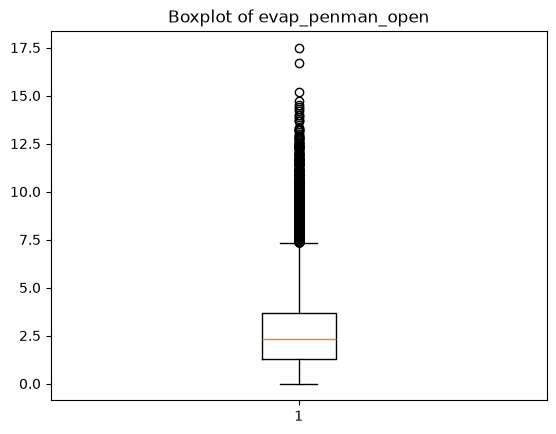

In [47]:
import matplotlib.pyplot as plt

plt.boxplot(df["evap_penman_open"].dropna())
plt.title("Boxplot of evap_penman_open")
plt.show()

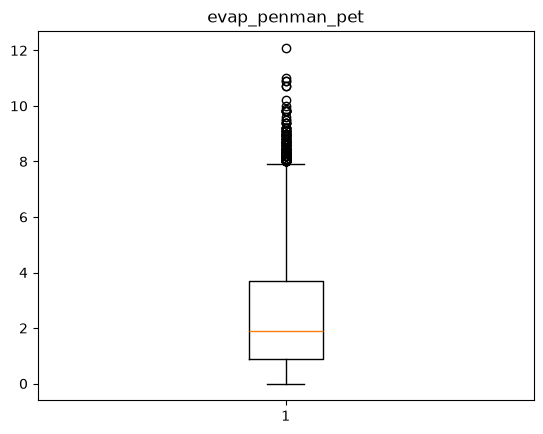

In [48]:


plt.boxplot(df["evap_penman_pet"].dropna())
plt.title("evap_penman_pet")
plt.show()

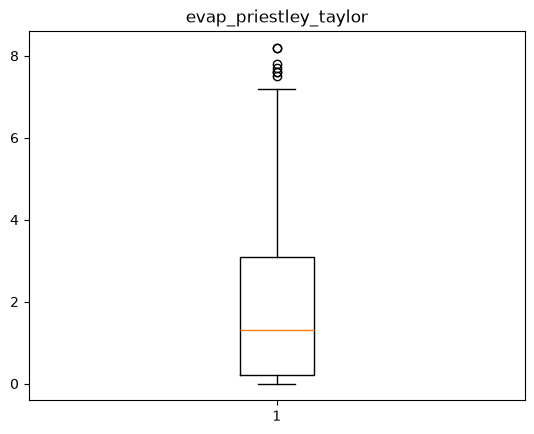

In [49]:


plt.boxplot(df["evap_priestley_taylor"].dropna())
plt.title("evap_priestley_taylor")
plt.show()

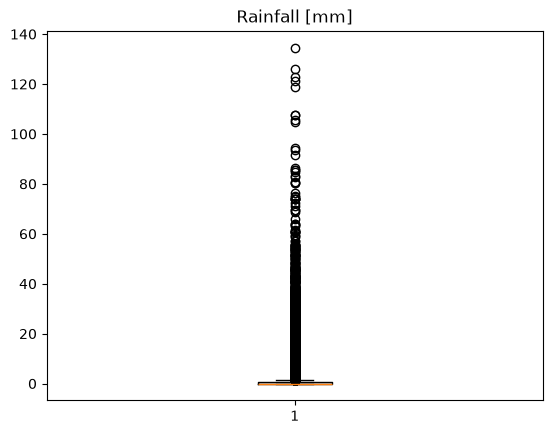

In [50]:


plt.boxplot(df["Rainfall [mm]"].dropna())
plt.title("Rainfall [mm]")
plt.show()

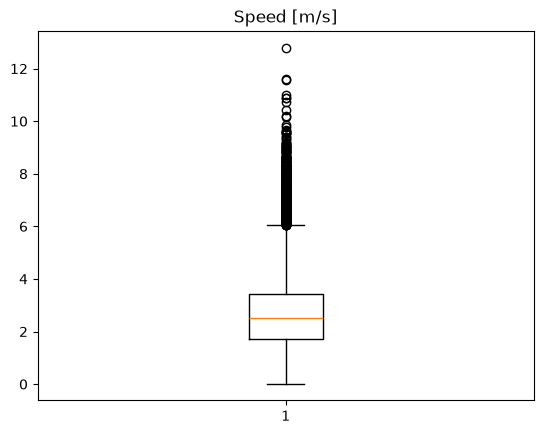

In [51]:


plt.boxplot(df["Speed [m/s]"].dropna())
plt.title("Speed [m/s]")
plt.show()

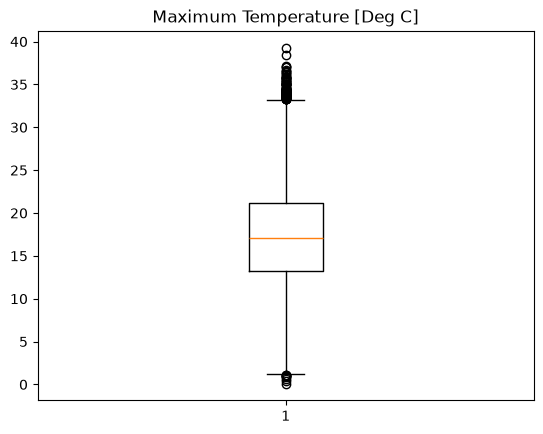

In [52]:


plt.boxplot(df["Maximum Temperature [Deg C]"].dropna())
plt.title("Maximum Temperature [Deg C]")
plt.show()

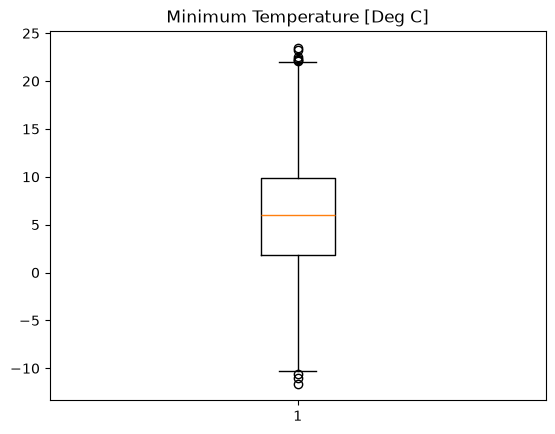

In [53]:


plt.boxplot(df["Minimum Temperature [Deg C]"].dropna())
plt.title("Minimum Temperature [Deg C]")
plt.show()

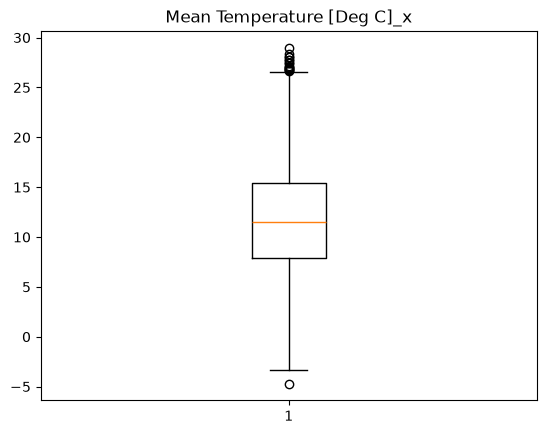

In [54]:
plt.boxplot(df["Mean Temperature [Deg C]_x"].dropna())
plt.title("Mean Temperature [Deg C]_x")
plt.show()

So we can see that all the attributes have some outliers, especially many outliers for rainfall or evaporation. However, all of them are within the range of weather that can happen in NZ. Keeping them, therefore, will provide informaiton of the weather. Therefore, I will not remove these outliers. 

Next I wil run the correlation

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

                             evap_penman_open  evap_penman_pet  \
evap_penman_open                     1.000000         0.885103   
evap_penman_pet                      0.885103         1.000000   
evap_priestley_taylor                0.665984         0.932714   
Rainfall [mm]                       -0.142950        -0.163591   
Speed [m/s]                          0.391412         0.383579   
Maximum Temperature [Deg C]          0.770466         0.786827   
Minimum Temperature [Deg C]          0.486561         0.588254   
Mean Temperature [Deg C]_x           0.697711         0.760739   

                             evap_priestley_taylor  Rainfall [mm]  \
evap_penman_open                          0.665984      -0.142950   
evap_penman_pet                           0.932714      -0.163591   
evap_priestley_taylor                     1.000000      -0.156000   
Rainfall [mm]                            -0.156000       1.000000   
Speed [m/s]                               0.266438       0.1

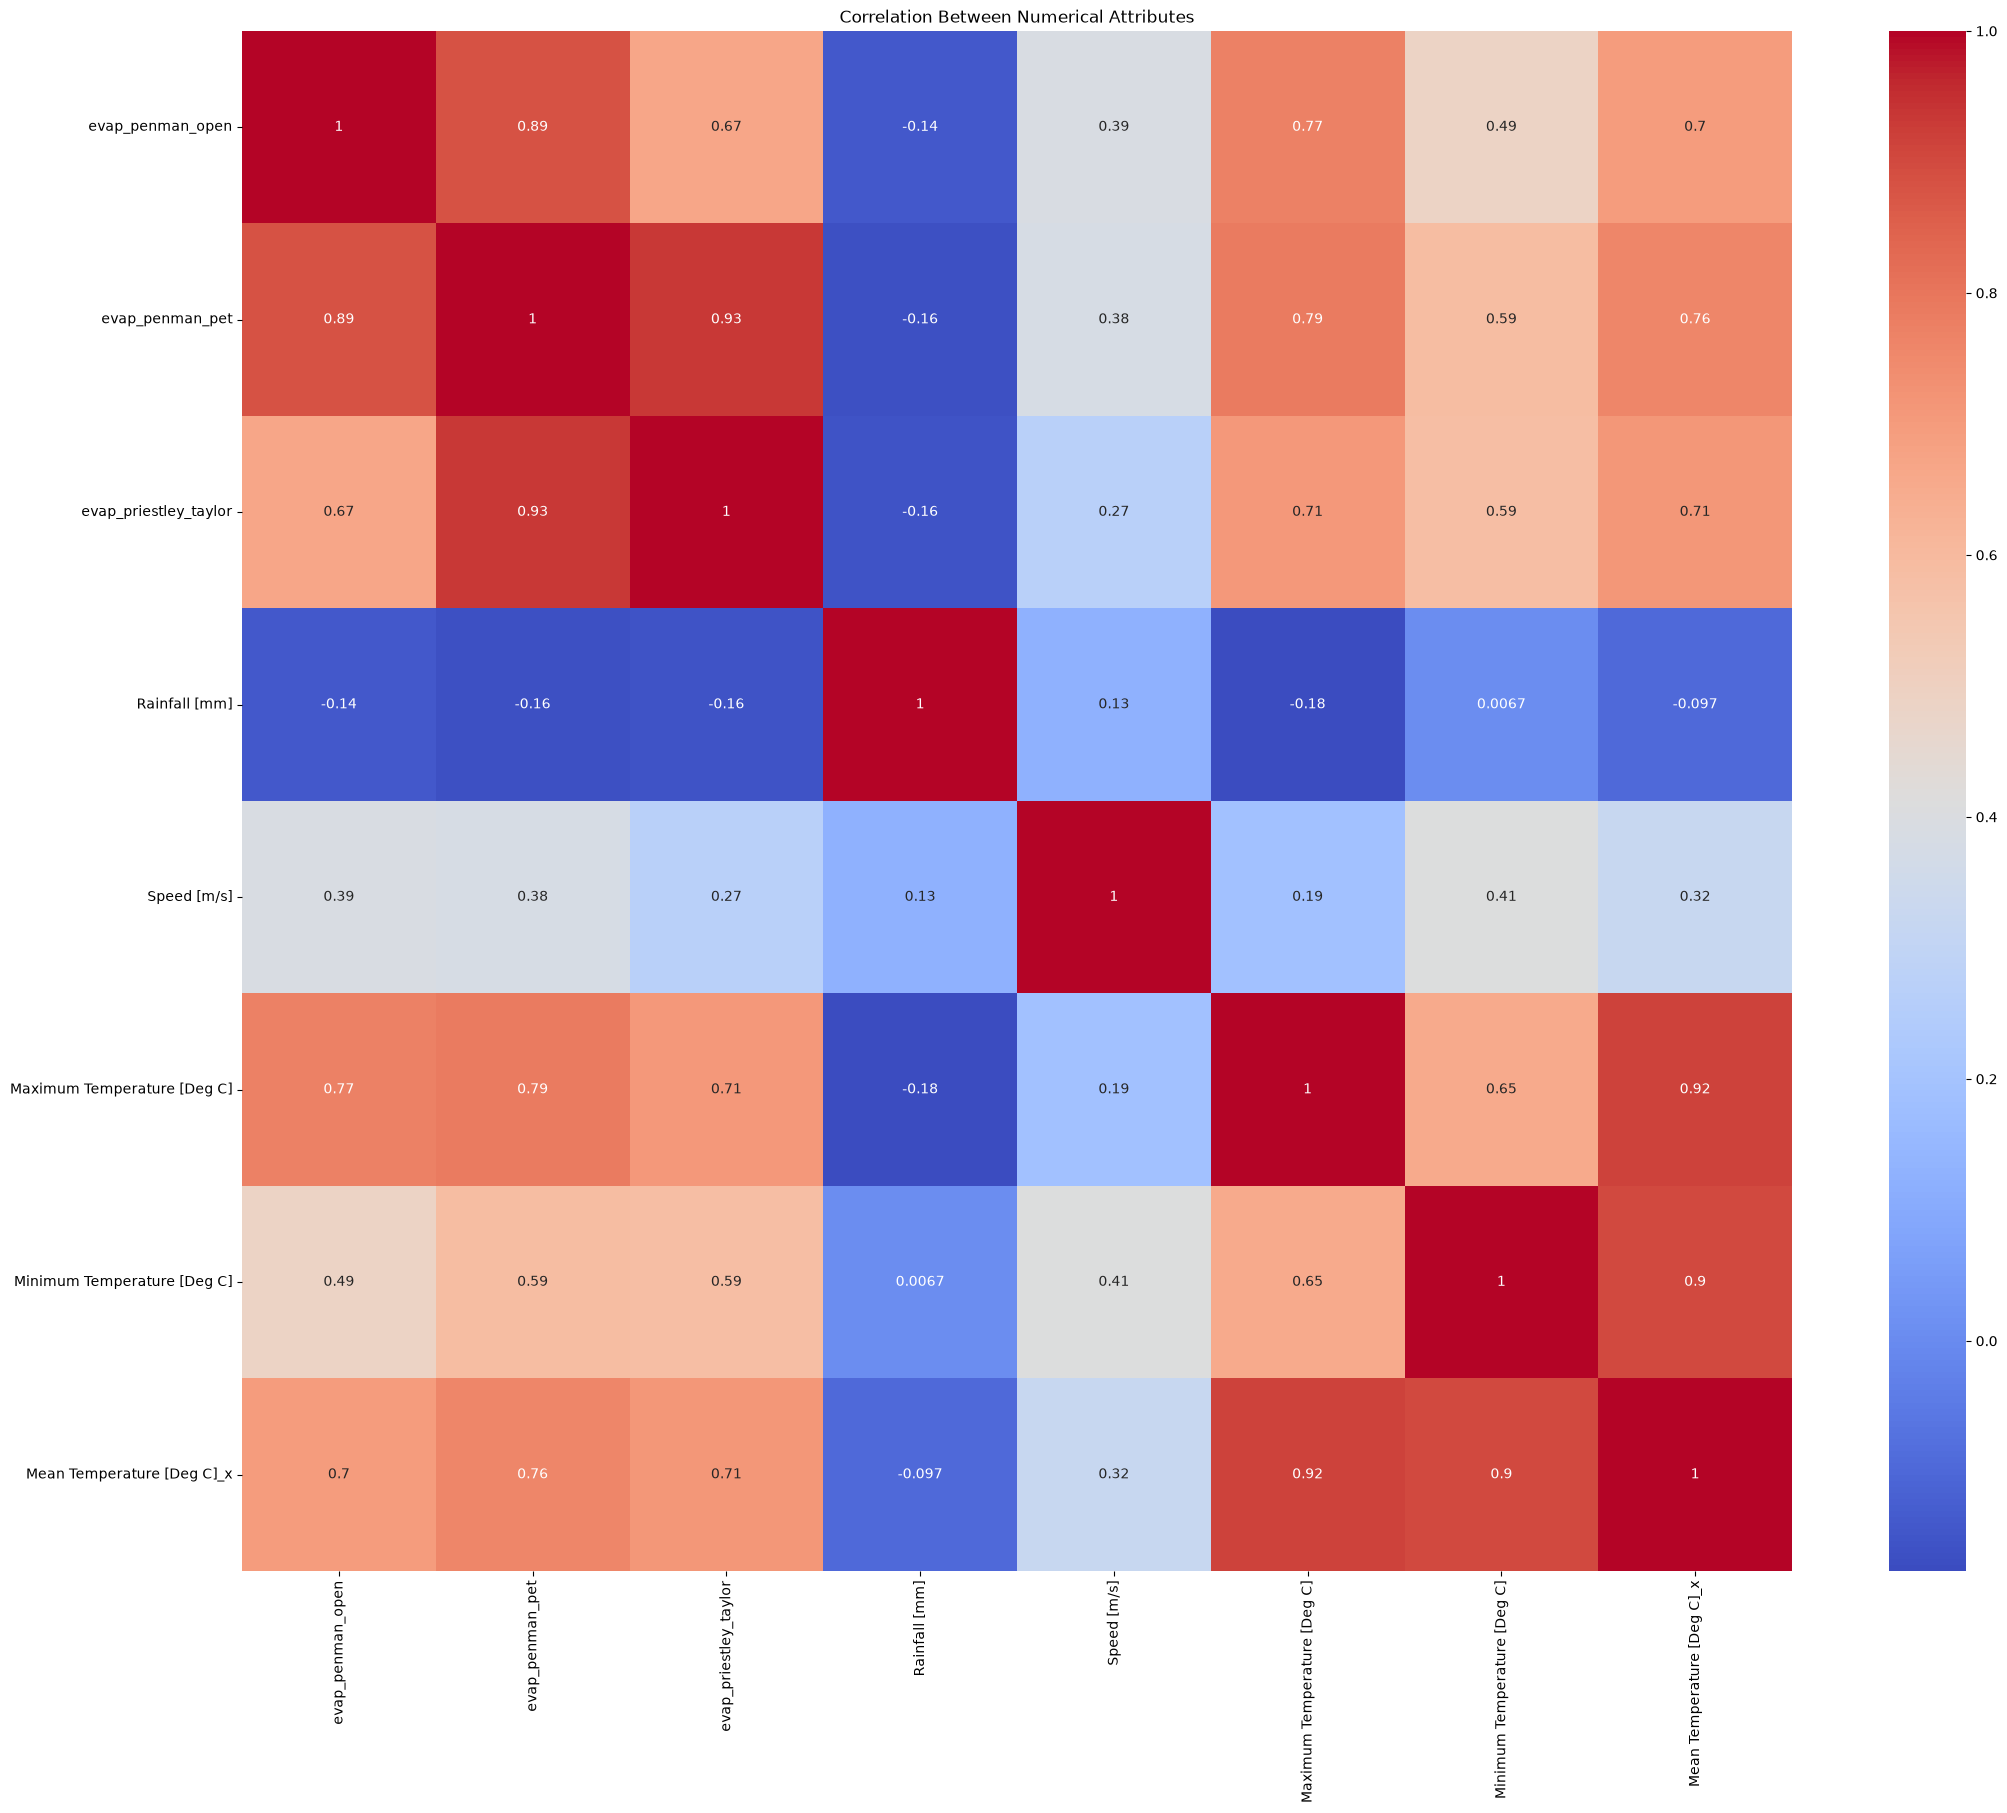

In [56]:
correlation_matrix = df.drop(columns=['Observation time UTC_x', "Station"]).corr()

# Display
print(correlation_matrix)

# Heatmap visualization
plt.figure(figsize=(25, 20))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Between Numerical Attributes')
plt.savefig('correlation.png', dpi=300, bbox_inches='tight')
plt.show()

So we can see that the target variable: mean temperature has highest correlation with the max and min temperature on the day and evaporation (prestly, pet, open). The correlation with wind is lower and the correlation with the rainfall is low and negative. Given that the correlation coeficient show that all of these variables somehow have some correlation with the target variable so I will select all of these attributes to run the forecast model. 

1.2 Data Preparation 
Keep all original files in data/raw/ unchanged. Create a cleaned, merged CSV file with 
daily weather data per station in data/processed/.  

Create the file in the folder: 

In [57]:
df.to_csv(
    "../data/clean/Pre-processed Data.csv",
    index=False
)

1.3 Summary 
Summarise the key findings and explain the data preparation steps, including how you 
handled missing values, outliers, scaling, and feature selection. 

So in this part I have preprocessed the data: 
First of all for each station, I merge the dataset to extract the attributes that we need to study in one dataset. The merge I used "inner" to make sure that I only keep the data when we have the data. For each dataset I also make sure that the date columns are converted to date type at the beginning so that it will be easier for analysis. 

Then I combined these five combined datasets together, that the information of the focused attributes and names of the station are kept in one file. 

Then I checked the missign values in this file. I see that the target attribute have just around 4% missing values. Because this value is important for forecasting so I remove them to be safe to make sure that the values I used for the forecast are good quality ones. 

I also checked the outliers and see the attributes have some outliers. However, as their value range are still within the range of normal weather values in terms of rainfall, evaporation and temperature so I did not remove them, instead I keep them as I think they will provide meaningful information for the forecast

I did not scale the attributes yet I think they can be scale differently between the train or test data so I will do the scaling the next step

Finally, the correlation analysis shows that all attributes have some correlation with the target attributes, some are high, some are low, but I will keep them all as I think they will help to increase the quality of the model that will be developed. 